<h2 style="color:rgb(0,120,170)">Create data for runtime comparison</h2>

Maps for comparing the Visibility Graph, RRT\* and PRM. Obstacle shapes are generated with [`polygenerator`](https://pypi.org/project/polygenerator/) (`pip install polygenerator`).

The generation code is in `utils/maps_generation_utils.py`, the plotting code in `utils/plot_utils.py`.

Every map is 10 × 10, with start **(0, 0)** and goal **(10, 10)**. Each batch has 10 maps:

1) different amount of obstacles (2–7, convex)
2) convex/concave obstacles (star-shaped, mostly concave)
3) no obstacles
4) obstacles make no impact (the straight line from start to goal is kept free)
5) few obstacles (2)
6) many obstacles (7)
7) random placement (no minimum distance between obstacles, centres anywhere on the map)

In [1]:
import random

from utils.maps_generation_utils import (
    END,
    MAP_SIZE,
    START,
    generate_complex_obstacle,
    generate_map,
    generate_simple_obstacle,
    save_batches,
)
from utils.plot_utils import plot

### Settings
A fixed seed makes every batch reproducible: re-running the notebook gives the same maps.

In [2]:
SEED = 42
MAPS_PER_BATCH = 10

random.seed(SEED)  # polygenerator uses Python's `random` module, so this seeds it too

### How the maps are generated
- **Simple obstacle** (`generate_simple_obstacle`): random convex polygon with 3–5 vertices.
- **Complex obstacle** (`generate_complex_obstacle`): random star-shaped polygon with 5–8 vertices (usually concave).
- `polygenerator` returns polygons inside the unit square; they are moved to a random centre and scaled to a random radius (0.6–1.5).

`generate_map` rejects and re-draws an obstacle if its centre is too close to another one, if its shape overlaps another obstacle (the Visibility Graph needs non-overlapping polygons), if it covers the start or goal, or (with `keep_line_clear=True`) if it touches the straight start–goal line.

Plots: gray = obstacles, green = start, blue = goal.

### Batch 1: different amount of obstacles
2–7 convex obstacles per map.

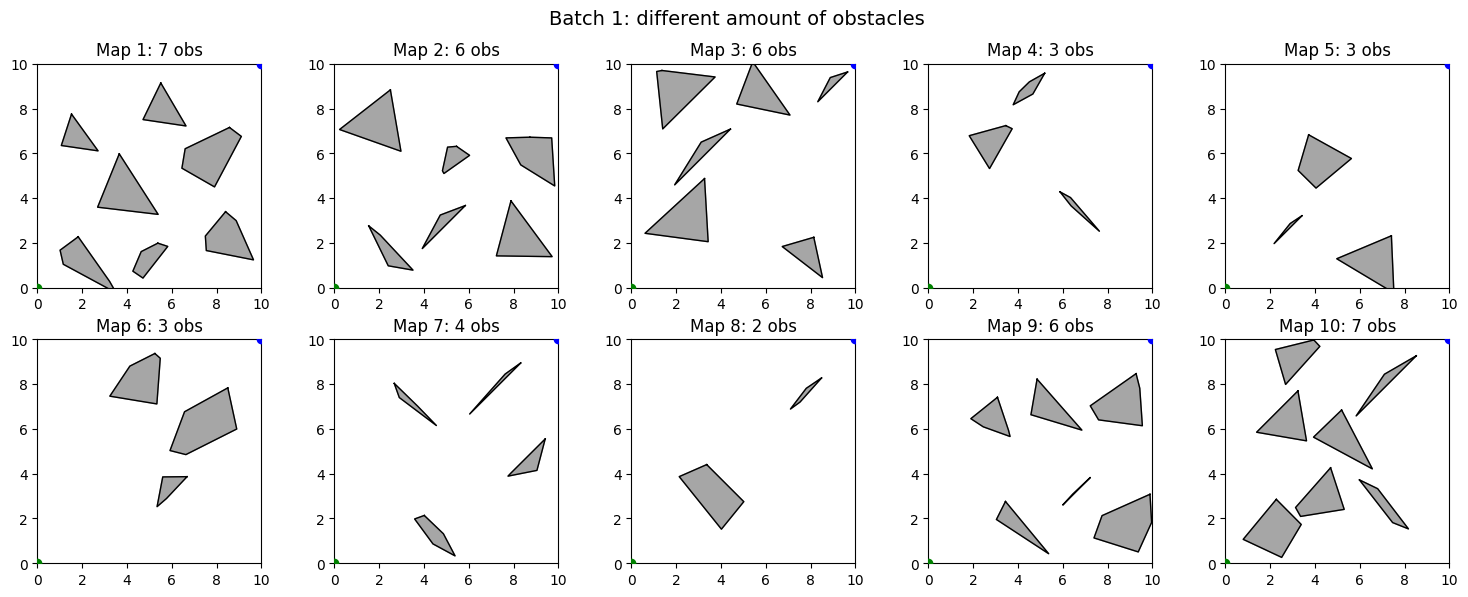

In [3]:
batch1 = [generate_map(generate_simple_obstacle) for _ in range(MAPS_PER_BATCH)]

plot(batch1, "Batch 1: different amount of obstacles")

### Batch 2: convex/concave obstacles
2–7 star-shaped (mostly concave) obstacles per map.

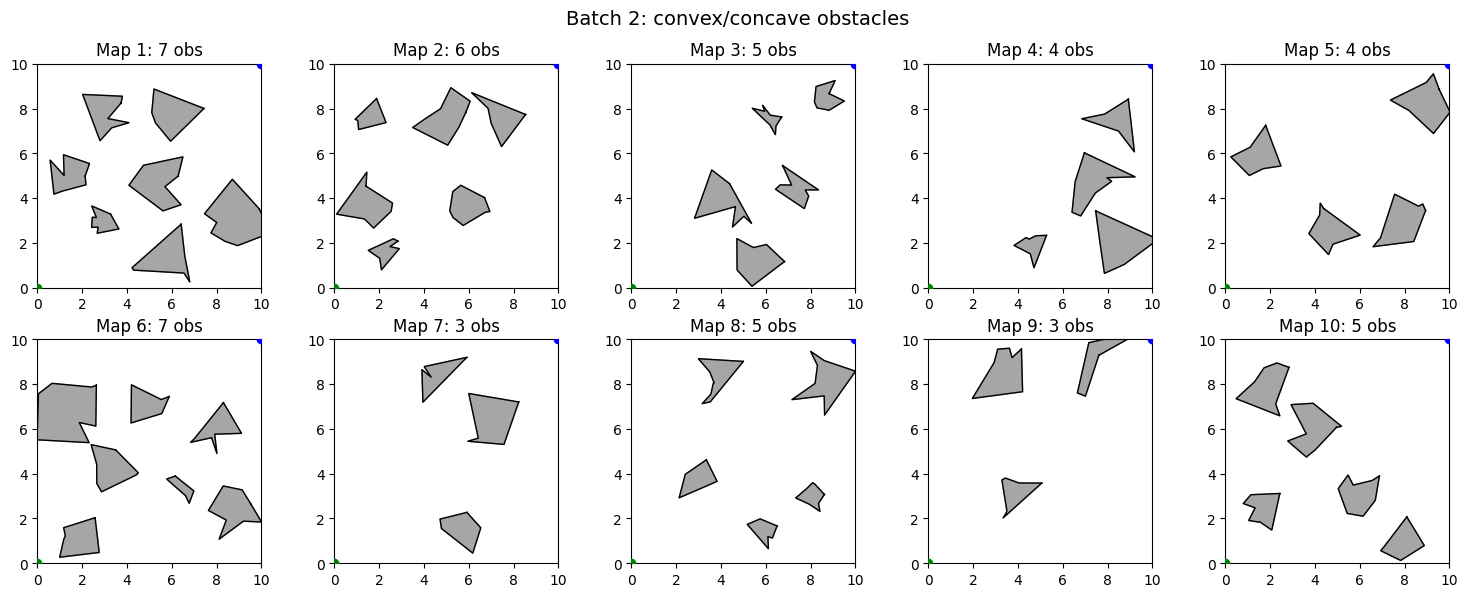

In [4]:
batch2 = [generate_map(generate_complex_obstacle) for _ in range(MAPS_PER_BATCH)]

plot(batch2, "Batch 2: convex/concave obstacles")

### Batch 3: no obstacles
Empty maps: the shortest path is the straight line.

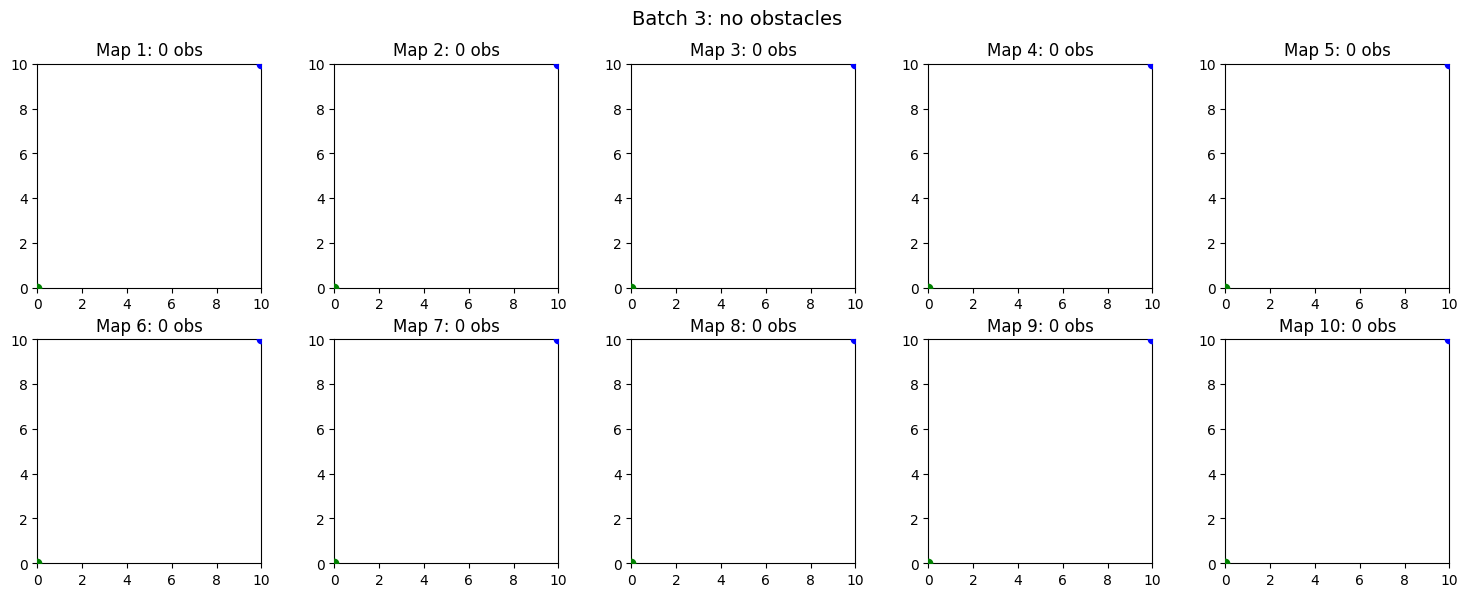

In [5]:
batch3 = [[] for _ in range(MAPS_PER_BATCH)]

plot(batch3, "Batch 3: no obstacles")

### Batch 4: obstacles make no impact
Obstacles are placed away from the straight start–goal line (red dashed), so the shortest path is still the straight line, but the planners still have to process the obstacles.

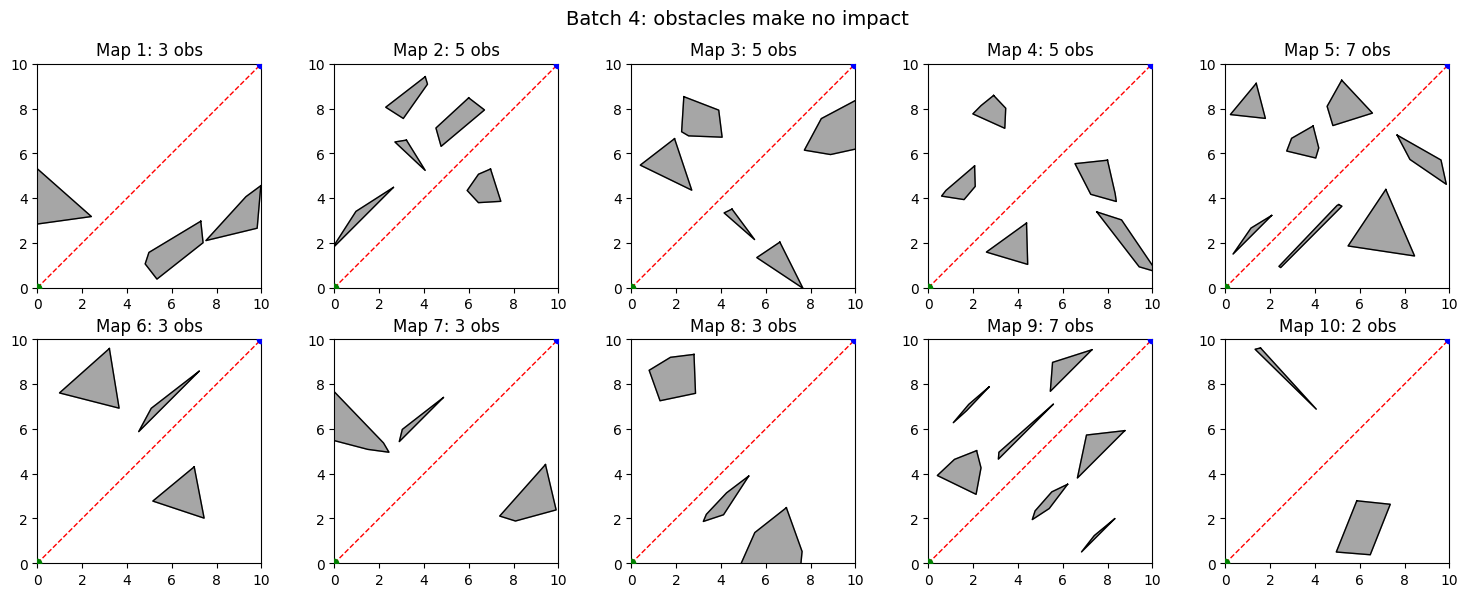

In [6]:
batch4 = [
    generate_map(generate_simple_obstacle, keep_line_clear=True)
    for _ in range(MAPS_PER_BATCH)
]

plot(batch4, "Batch 4: obstacles make no impact", show_line=True)

### Batch 5: few obstacles
Exactly 2 convex obstacles per map.

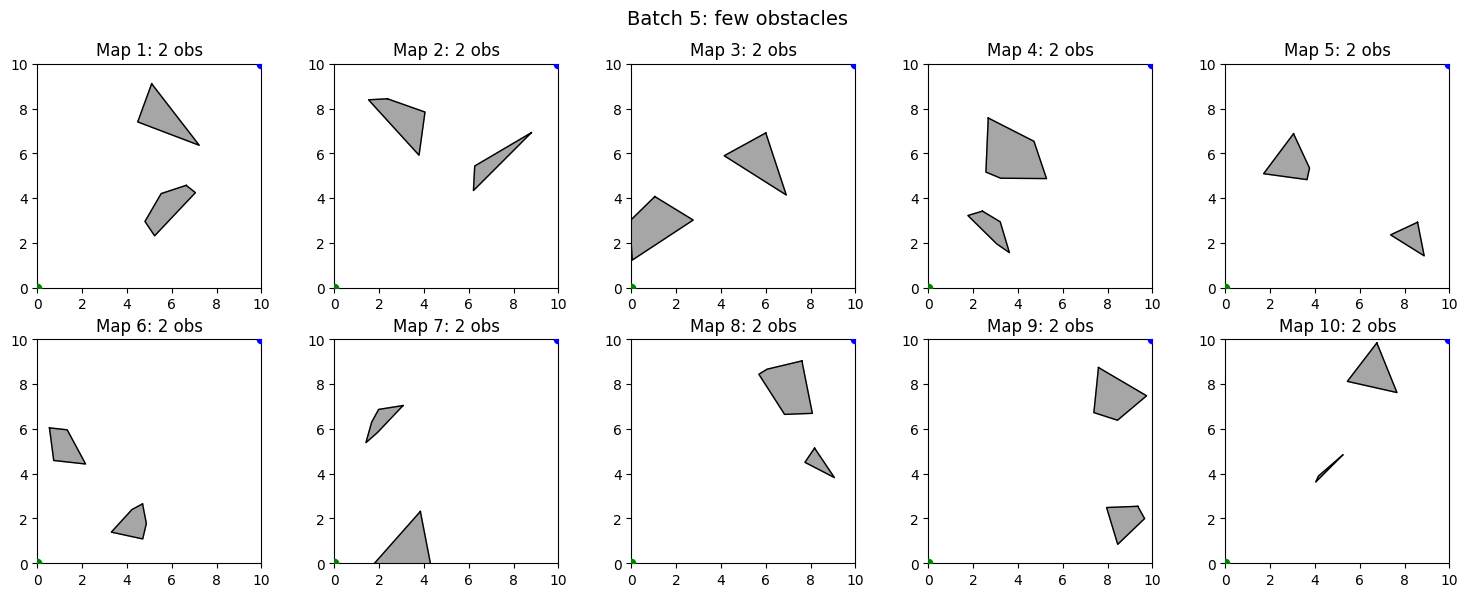

In [7]:
batch5 = [generate_map(generate_simple_obstacle, n_obstacle=2) for _ in range(MAPS_PER_BATCH)]

plot(batch5, "Batch 5: few obstacles")

### Batch 6: many obstacles
Exactly 7 convex obstacles per map.

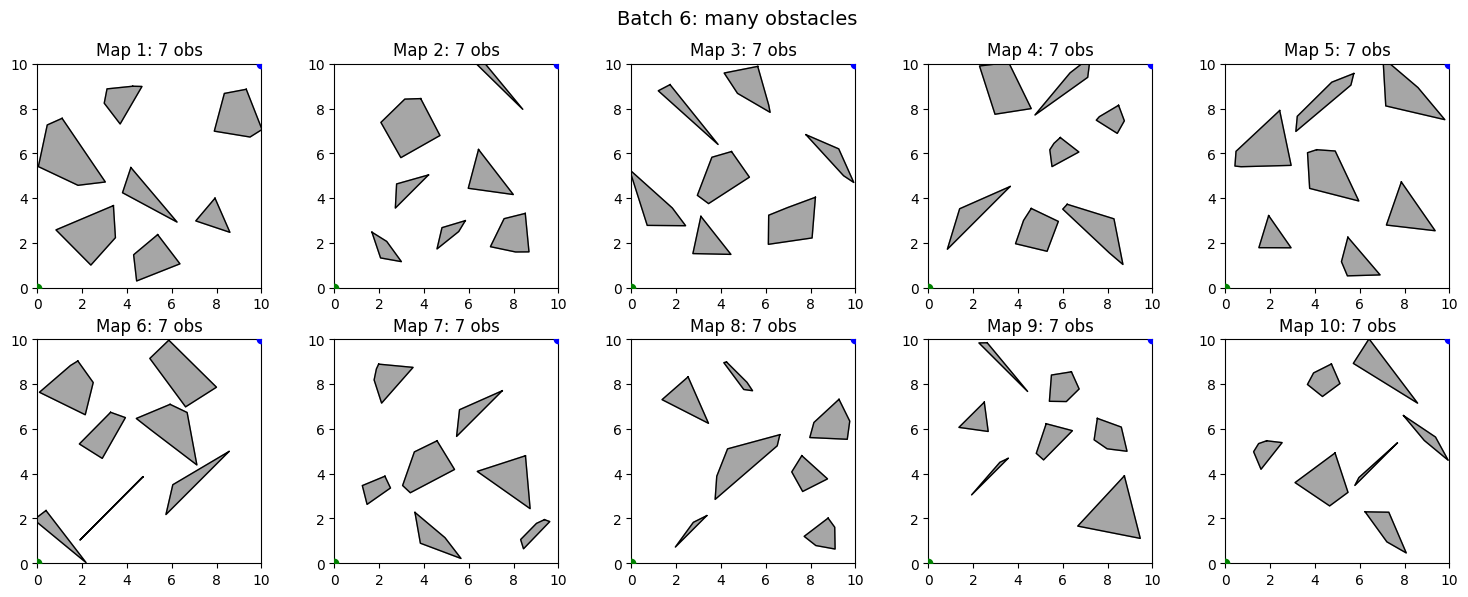

In [8]:
batch6 = [generate_map(generate_simple_obstacle, n_obstacle=7) for _ in range(MAPS_PER_BATCH)]

plot(batch6, "Batch 6: many obstacles")

### Batch 7: random placement
No minimum distance between centres and centres can be anywhere on the map, including the border. Obstacles still don't overlap and don't cover the start or goal.

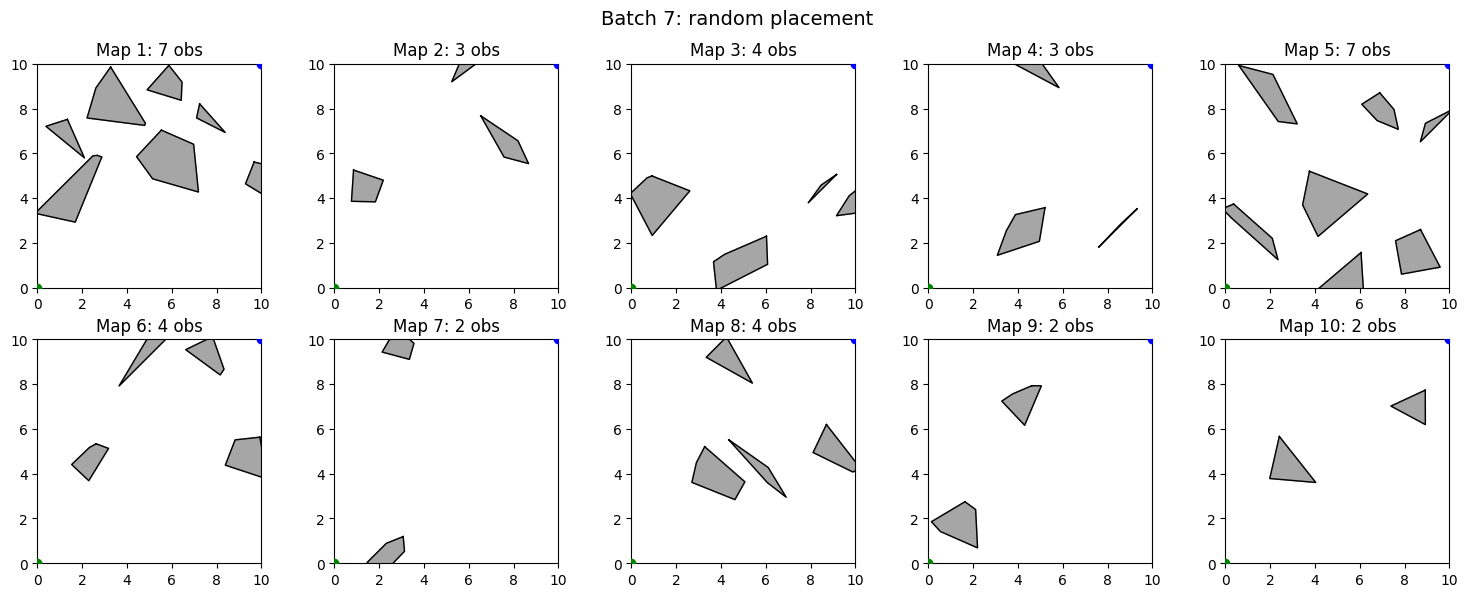

In [9]:
batch7 = [
    generate_map(generate_simple_obstacle, min_distance=0, margin=0)
    for _ in range(MAPS_PER_BATCH)
]

plot(batch7, "Batch 7: random placement")

### Save the batches
Saved to `maps/maps_batches.json` so the comparison can load exactly the same maps:

```python
from utils.maps_generation_utils import load_batches
obstacle_batches = load_batches("maps/maps_batches.json")
```

In [11]:
obstacle_batches = [batch1, batch2, batch3, batch4, batch5, batch6, batch7]

save_batches("maps/maps_batches.json", obstacle_batches, seed=SEED)
print("saved", sum(len(b) for b in obstacle_batches), "maps")

saved 70 maps
